# Notebook 1 — From RNN to State Space Model

**Goal:** understand a state space model (SSM) as a *discretized continuous-time linear system*, and verify the discretization is correct by comparing it against a numerical ODE solver.

This is the first of three notebooks building up to Mamba:
1. **This notebook** — discretizing a fixed continuous-time linear system.
2. Notebook 2 — making the system *selective* (input-dependent), and testing it on a toy task.
3. Notebook 3 — the parallel scan that makes selective SSMs fast on a GPU.

**Prerequisites:** basic linear algebra, one prior RNN or attention implementation, basic PyTorch.

In [1]:
import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)

## 1. The continuous-time system

A linear state space model describes how a hidden state $h(t) \in \mathbb{R}$ evolves continuously in response to an input $x(t)$:

$$
\frac{dh}{dt} = a \, h(t) + b \, x(t), \qquad y(t) = c \, h(t)
$$

For $a < 0$ this system is stable: with no input, $h(t)$ decays exponentially. This is exactly the kind of system studied in classical control theory, and it's the starting point for S4 and Mamba.

We'll integrate this system numerically (with RK4) to get a **ground-truth trajectory** we can check our discretization against.

In [2]:
a = -0.8   # negative => stable, decaying system
b = 1.0
c = 1.0

def rk4_ground_truth(a, b, x_seq, dt, h0=0.0):
    """Integrate dh/dt = a*h + b*x with RK4, holding x constant (zero-order hold) within each step."""
    h = h0
    hs = []
    for x in x_seq:
        f = lambda hh: a * hh + b * x
        k1 = f(h)
        k2 = f(h + 0.5 * dt * k1)
        k3 = f(h + 0.5 * dt * k2)
        k4 = f(h + dt * k3)
        h = h + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
        hs.append(h)
    return torch.tensor(hs)

## 2. Discretizing the system (zero-order hold)

We can't feed a continuous system into a neural net that processes discrete tokens. We need a **discrete recurrence** $h_t = \bar{a}\, h_{t-1} + \bar{b}\, x_t$ that matches the continuous system at each timestep, for some step size $\Delta$.

The *zero-order hold* (ZOH) discretization — assuming $x$ is held constant over each interval of length $\Delta$ — gives a closed form:

$$
\bar{a} = e^{a \Delta}, \qquad \bar{b} = \frac{\bar{a} - 1}{a}\, b
$$

This is exactly the discretization rule used inside S4 and Mamba (Mamba uses the same ZOH rule, applied per-channel, with a learned, input-dependent $\Delta$ — that's Notebook 2).

In [3]:
def discretize_zoh(a, b, dt):
    a_bar = torch.exp(torch.tensor(a * dt))
    b_bar = (a_bar - 1) / a * b if a != 0 else b * dt
    return a_bar.item(), b_bar

def discrete_recurrence(a_bar, b_bar, x_seq, h0=0.0):
    h = h0
    hs = []
    for x in x_seq:
        h = a_bar * h + b_bar * x
        hs.append(h)
    return torch.tensor(hs)

## 3. Checking the discretization against the ODE solution

If the ZOH discretization is correct, the discrete recurrence should trace out (almost) the same trajectory as RK4 integration of the continuous system.

a_bar = 0.9608, b_bar = 0.0490
max abs error between RK4 ground truth and ZOH discretization: 5.96e-08


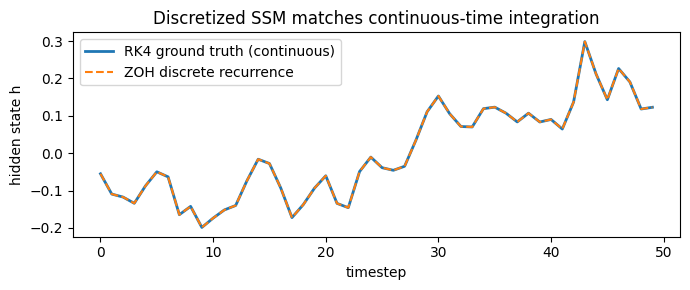

In [4]:
L = 50
dt = 0.05
x_seq = torch.randn(L)

gt = rk4_ground_truth(a, b, x_seq, dt)
a_bar, b_bar = discretize_zoh(a, b, dt)
disc = discrete_recurrence(a_bar, b_bar, x_seq)

err = (gt - disc).abs().max().item()
print(f"a_bar = {a_bar:.4f}, b_bar = {b_bar:.4f}")
print(f"max abs error between RK4 ground truth and ZOH discretization: {err:.2e}")

plt.figure(figsize=(7, 3))
plt.plot(gt, label="RK4 ground truth (continuous)", linewidth=2)
plt.plot(disc, "--", label="ZOH discrete recurrence")
plt.xlabel("timestep")
plt.ylabel("hidden state h")
plt.title("Discretized SSM matches continuous-time integration")
plt.legend()
plt.tight_layout()
plt.show()

## 4. This *is* a linear RNN

Unroll the recurrence $h_t = \bar{a}\, h_{t-1} + \bar{b}\, x_t$ — this is precisely a linear RNN with a single fixed transition weight $\bar{a}$ and a single fixed input weight $\bar{b}$, shared across every timestep.

Two things are worth noticing, and both motivate Notebook 2:

1. Because $\bar{a}, \bar{b}$ are constants (not learned per-timestep functions of the input), this system treats every input the same way — it has **no way to "decide" what to remember**.
2. Because the recurrence is linear, the sequence of outputs $y_1, \dots, y_L$ can be written as a **convolution** of the input with a fixed kernel $(\bar{c}\bar{b}, \bar{c}\bar{a}\bar{b}, \bar{c}\bar{a}^2\bar{b}, \dots)$ — this is exactly the trick S4 uses to train in parallel via FFT convolution. Mamba gives up this convolution view in exchange for *selectivity* (Notebook 2), which is why it needs a different parallelization strategy (Notebook 3).

## Exercise

1. By hand, derive $\bar a, \bar b$ for $a=-2, b=3, \Delta=0.1$ and check your answer against `discretize_zoh`.
2. Vary `dt` in the cell above (try `0.5` and `2.0`). At what point does the discrete recurrence stop tracking the continuous system well, and why?
3. Set `a = 0.8` (positive, unstable) and re-run. What happens to $h_t$ as $t$ grows? Why might this be a problem for a deep sequence model?